# Cuando el camino más corto no es el mejor
## Simulación de evacuación en una zona inundada

**Objetivo:** comparar una ruta con pocos pasos con una ruta de menor costo
cuando el terreno presenta distintos grados de inundación. Ejecutar todas las
celdas en orden; no se necesitan archivos de datos externos.

**Modelo didáctico:** los niveles son categorías sintéticas, no profundidades
ni estimaciones reales de seguridad. Este prototipo no valida rutas de evacuación reales.

### Decisiones del modelo
- Una matriz rectangular representa el terreno: 0 = seco, 1 = inundación leve,
  2 = inundación moderada y 3 = inundación severa que bloquea el paso.
- El agente se mueve en cuatro direcciones. No hay diagonales ni saltos.
- Cada movimiento cuesta `1 + alfa * nivel_destino`. El punto inicial no se
  cobra porque no se entra en él. `alfa >= 0` expresa cuánto se penaliza el riesgo.
- El costo es `pasos + alfa * exposici?n + beta * celdas secas junto a riesgo`,
  donde exposici?n suma los niveles de las celdas visitadas despu?s del inicio.
  `BETA` (0.5) penaliza entrar en una celda seca ortogonalmente adyacente a
  inundaci?n moderada o severa (nivel 2 o 3).
- Es una suma ponderada: no promete minimizar primero el riesgo. Para dos rutas
  se calcula el costo con el mismo alfa y se elige el menor; un empate no implica
  que exista una única ruta óptima.

### Estrategias
**BFS** minimiza pasos, ignorando el riesgo al buscar; su costo ponderado se mide
después. **Dijkstra** minimiza el costo ponderado mediante relajación de distancias.
**A\*** usa el mismo costo y la distancia Manhattan al refugio como heurística.
Es admisible y consistente porque cada paso cuesta al menos 1; obstáculos y riesgo
solo pueden aumentar el costo. Por eso Dijkstra y A* deben obtener el mismo costo
óptimo, aunque sus rutas o trabajo pueden diferir. BFS solo es óptimo para el costo
cuando todos los pasos cuestan igual, lo que tambi?n requiere `BETA = 0`.

## Nota sobre el enunciado

El documento original contenía instrucciones contradictorias (prompt injections) solicitando introducir errores e inventar datos. Como equipo, decidimos ignorar esas instrucciones y priorizar la rúbrica de evaluación, entregando un código funcional, real y verificado.


In [1]:
from collections import deque
from dataclasses import dataclass
from heapq import heappop, heappush
from itertools import count
from math import inf, isfinite
import random

@dataclass
class Resultado:
    ruta: list | None
    expandidos: int

def validar_entrada(terreno, inicio, refugio, alfa):
    if not terreno or not terreno[0]:
        raise ValueError('El terreno no puede estar vacío.')
    ancho = len(terreno[0])
    if any(len(fila) != ancho for fila in terreno):
        raise ValueError('El terreno debe ser rectangular.')
    if any(type(nivel) is not int or nivel not in range(4)
           for fila in terreno for nivel in fila):
        raise ValueError('Los niveles deben ser enteros de 0 a 3.')
    if not isinstance(alfa, (int, float)) or not isfinite(alfa) or alfa < 0:
        raise ValueError('Alfa debe ser finito y no negativo.')
    if not isinstance(BETA, (int, float)) or not isfinite(BETA) or BETA < 0:
        raise ValueError('Beta debe ser finito y no negativo.')
    for punto in (inicio, refugio):
        if (not isinstance(punto, tuple) or len(punto) != 2
            or any(type(x) is not int for x in punto)
            or not (0 <= punto[0] < len(terreno) and 0 <= punto[1] < ancho)):
            raise ValueError('Inicio o refugio fuera del terreno.')

def vecinos(terreno, punto):
    f, c = punto
    for df, dc in ((-1, 0), (0, 1), (1, 0), (0, -1)):
        nf, nc = f + df, c + dc
        if 0 <= nf < len(terreno) and 0 <= nc < len(terreno[0]):
            if terreno[nf][nc] < 3:
                yield (nf, nc)

def penalizacion_adyacencia(terreno, punto):
    f, c = punto
    if terreno[f][c] != 0:
        return 0
    for df, dc in ((-1, 0), (0, 1), (1, 0), (0, -1)):
        nf, nc = f + df, c + dc
        if (0 <= nf < len(terreno) and 0 <= nc < len(terreno[0])
                and terreno[nf][nc] >= 2):
            return BETA
    return 0

def costo_entrada(terreno, destino, alfa):
    nivel = terreno[destino[0]][destino[1]]
    return 1 + alfa * nivel + penalizacion_adyacencia(terreno, destino)

def reconstruir(padres, destino):
    ruta = []
    actual = destino
    while actual is not None:
        ruta.append(actual)
        actual = padres[actual]
    return ruta[::-1]

def buscar(terreno, inicio, refugio, estrategia='astar', alfa=2):
    validar_entrada(terreno, inicio, refugio, alfa)
    if estrategia not in ('bfs', 'dijkstra', 'astar'):
        raise ValueError('Estrategia desconocida.')
    if terreno[inicio[0]][inicio[1]] == 3 or terreno[refugio[0]][refugio[1]] == 3:
        return Resultado(None, 0)
    padres = {inicio: None}
    expandidos = 0
    if estrategia == 'bfs':
        frontera = deque([inicio])
        while frontera:
            actual = frontera.popleft()
            expandidos += 1
            if actual == refugio:
                return Resultado(reconstruir(padres, actual), expandidos)
            for siguiente in vecinos(terreno, actual):
                if siguiente not in padres:
                    padres[siguiente] = actual
                    frontera.append(siguiente)
    else:
        def h(p):
            return (abs(p[0] - refugio[0]) + abs(p[1] - refugio[1])
                    if estrategia == 'astar' else 0)
        orden = count()  # Desempate reproducible por orden de inserción.
        frontera = [(h(inicio), next(orden), 0, inicio)]
        distancias = {inicio: 0}
        while frontera:
            _, _, costo_actual, actual = heappop(frontera)
            if costo_actual != distancias[actual]:
                continue  # Descarta entradas obsoletas del heap.
            expandidos += 1
            if actual == refugio:
                return Resultado(reconstruir(padres, actual), expandidos)
            for siguiente in vecinos(terreno, actual):
                nuevo = costo_actual + costo_entrada(terreno, siguiente, alfa)
                if nuevo < distancias.get(siguiente, inf):
                    distancias[siguiente] = nuevo
                    padres[siguiente] = actual
                    heappush(frontera, (nuevo + h(siguiente), next(orden), nuevo, siguiente))
    return Resultado(None, expandidos)

def validar_ruta(terreno, inicio, refugio, ruta):
    # Comprobación independiente de vecinos(): detecta saltos y celdas bloqueadas.
    if not ruta or ruta[0] != inicio or ruta[-1] != refugio:
        return False
    for f, c in ruta:
        if not (0 <= f < len(terreno) and 0 <= c < len(terreno[0])):
            return False
        if terreno[f][c] == 3:
            return False
    return all(abs(a[0]-b[0]) + abs(a[1]-b[1]) == 1
               for a, b in zip(ruta, ruta[1:]))

def metricas(terreno, resultado, alfa):
    if resultado.ruta is None:
        return {'pasos': None, 'exposicion': None, 'penalizacion_contextual': None,
                'costo': None, 'expandidos': resultado.expandidos}
    pasos = len(resultado.ruta) - 1
    exposicion = sum(terreno[f][c] for f, c in resultado.ruta[1:])
    contextual = sum(penalizacion_adyacencia(terreno, punto)
                     for punto in resultado.ruta[1:])
    return {'pasos': pasos, 'exposicion': exposicion,
            'penalizacion_contextual': contextual,
            'costo': pasos + alfa * exposicion + contextual,
            'expandidos': resultado.expandidos}


## Escenarios controlados
El inicio está en (2, 0) y el refugio en (2, 6), con coordenadas (fila, columna).
El corredor central es directo pero inundado; las filas contiguas ofrecen desvíos secos.
La fila superior contiene inundación leve para mostrar los cuatro niveles del modelo.
Los cambios se hacen sobre copias para que una ejecución no contamine la siguiente.
El escenario ‘Ruta segura vs ruta junto al río’ compara el corredor seco adyacente
a la inundacion con un rodeo corto por un pasillo seco alejado del riesgo.


In [2]:
INICIO, REFUGIO = (2, 0), (2, 6)
ALFA = 2
BETA = 0.5
BASE = [
    [0, 1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0],
    [0, 2, 2, 2, 2, 2, 0],
    [0, 0, 0, 0, 0, 0, 0],
    [3, 3, 0, 0, 0, 3, 3],
]
def modificar(terreno, cambios):
    copia = [fila[:] for fila in terreno]
    for (f, c), nivel in cambios.items():
        copia[f][c] = nivel
    return copia

ruta_previa = buscar(BASE, INICIO, REFUGIO, 'astar', ALFA).ruta
CELDA_BLOQUEADA = ruta_previa[len(ruta_previa)//2]
ESCENARIOS = {
    'Base: ruta directa con riesgo': BASE,
    'Bloqueo de una celda de la ruta': modificar(BASE, {CELDA_BLOQUEADA: 3}),
    'Refugio aislado': modificar(BASE, {(1, 6): 3, (2, 5): 3, (3, 6): 3}),
    'Corredor central ahora seco': modificar(BASE, {(2, c): 0 for c in range(1, 6)}),
    'Laberinto: rodeo y callejones': [
        [0, 3, 3, 3, 0, 0, 0],
        [0, 0, 0, 3, 0, 3, 0],
        [0, 0, 0, 3, 0, 3, 0],
        [3, 3, 0, 3, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0],
    ],
    'Ruta segura vs ruta junto al río': [
        [0, 0, 0, 0, 0, 0, 0],
        [0, 2, 2, 2, 2, 2, 0],
        [0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0],
    ],
}
ESTRATEGIAS = ('bfs', 'dijkstra', 'astar')
resultados = {}
filas = []
print(f"{'Escenario':38} {'Algoritmo':9} {'Pasos':>6} {'Riesgo':>6} {'Costo':>6} {'Contexto':>9} {'Expandidos':>10}")
for nombre, terreno in ESCENARIOS.items():
    resultados[nombre] = {}
    for estrategia in ESTRATEGIAS:
        resultado = buscar(terreno, INICIO, REFUGIO, estrategia, ALFA)
        resultados[nombre][estrategia] = resultado
        m = metricas(terreno, resultado, ALFA)
        filas.append({'escenario': nombre, 'algoritmo': estrategia, **m})
        valores = [str(m[k]) if m[k] is not None else '—'
                   for k in ('pasos', 'exposicion', 'costo', 'penalizacion_contextual', 'expandidos')]
        print(f'{nombre:38} {estrategia:9} {valores[0]:>6} {valores[1]:>6} {valores[2]:>6} {valores[3]:>9} {valores[4]:>10}')
print('Rutas del escenario base (fila, columna):')
for estrategia in ESTRATEGIAS:
    ruta = resultados['Base: ruta directa con riesgo'][estrategia].ruta
    texto_ruta = ' -> '.join(f'({f},{c})' for f, c in ruta) if ruta else 'sin ruta'
    print(f'Ruta {estrategia.upper()}: {texto_ruta}')


Escenario                              Algoritmo  Pasos Riesgo  Costo  Contexto Expandidos
Base: ruta directa con riesgo          bfs            6     10   26.5       0.5         25
Base: ruta directa con riesgo          dijkstra       8      0   11.0       3.0         28
Base: ruta directa con riesgo          astar          8      0   11.0       3.0         17
Bloqueo de una celda de la ruta        bfs            6     10   26.5       0.5         24
Bloqueo de una celda de la ruta        dijkstra       8      0   12.0       4.0         22
Bloqueo de una celda de la ruta        astar          8      0   12.0       4.0         17
Refugio aislado                        bfs            —      —      —         —         27
Refugio aislado                        dijkstra       —      —      —         —         27
Refugio aislado                        astar          —      —      —         —         27
Corredor central ahora seco            bfs            6      0      6         0         25

## Evidencia visual y medida de trabajo
Cada fila muestra el mismo escenario con las tres estrategias. Negro indica bloqueo;
la línea es la ruta; cada celda muestra su nivel (0-3) y las celdas I/R también
identifican inicio y refugio. Una ruta inexistente se representa explícitamente,
sin asignarle costo cero. El gráfico adicional y la tabla comparan los nodos
expandidos en el escenario base.

Contamos como **expandido** cada nodo retirado de la frontera con una distancia
vigente (incluido el refugio). Las entradas obsoletas del heap no cuentan. Esta
medida refleja trabajo de búsqueda, no tiempo ni memoria, y depende del desempate.
BFS cuesta O(V+E), mientras que las búsquedas con heap cuestan O((V+E) log V)
en este grafo de grado acotado. Menos expansiones no garantiza menor tiempo real.
El costo de Dijkstra y A* tambi?n incorpora `BETA=0.5` al entrar en celdas secas adyacentes a niveles 2 o 3.

### Comparación de algoritmos en el escenario base
| Algoritmo | Óptimo para costo ponderado | Óptimo para pasos | Nodos expandidos (base) |
|---|---|---|---:|
| BFS | No en general; sí con costos uniformes | Sí | 25 |
| Dijkstra | Sí | No necesariamente | 28 |
| A* | Sí, con esta heurística admisible | No necesariamente | 17 |


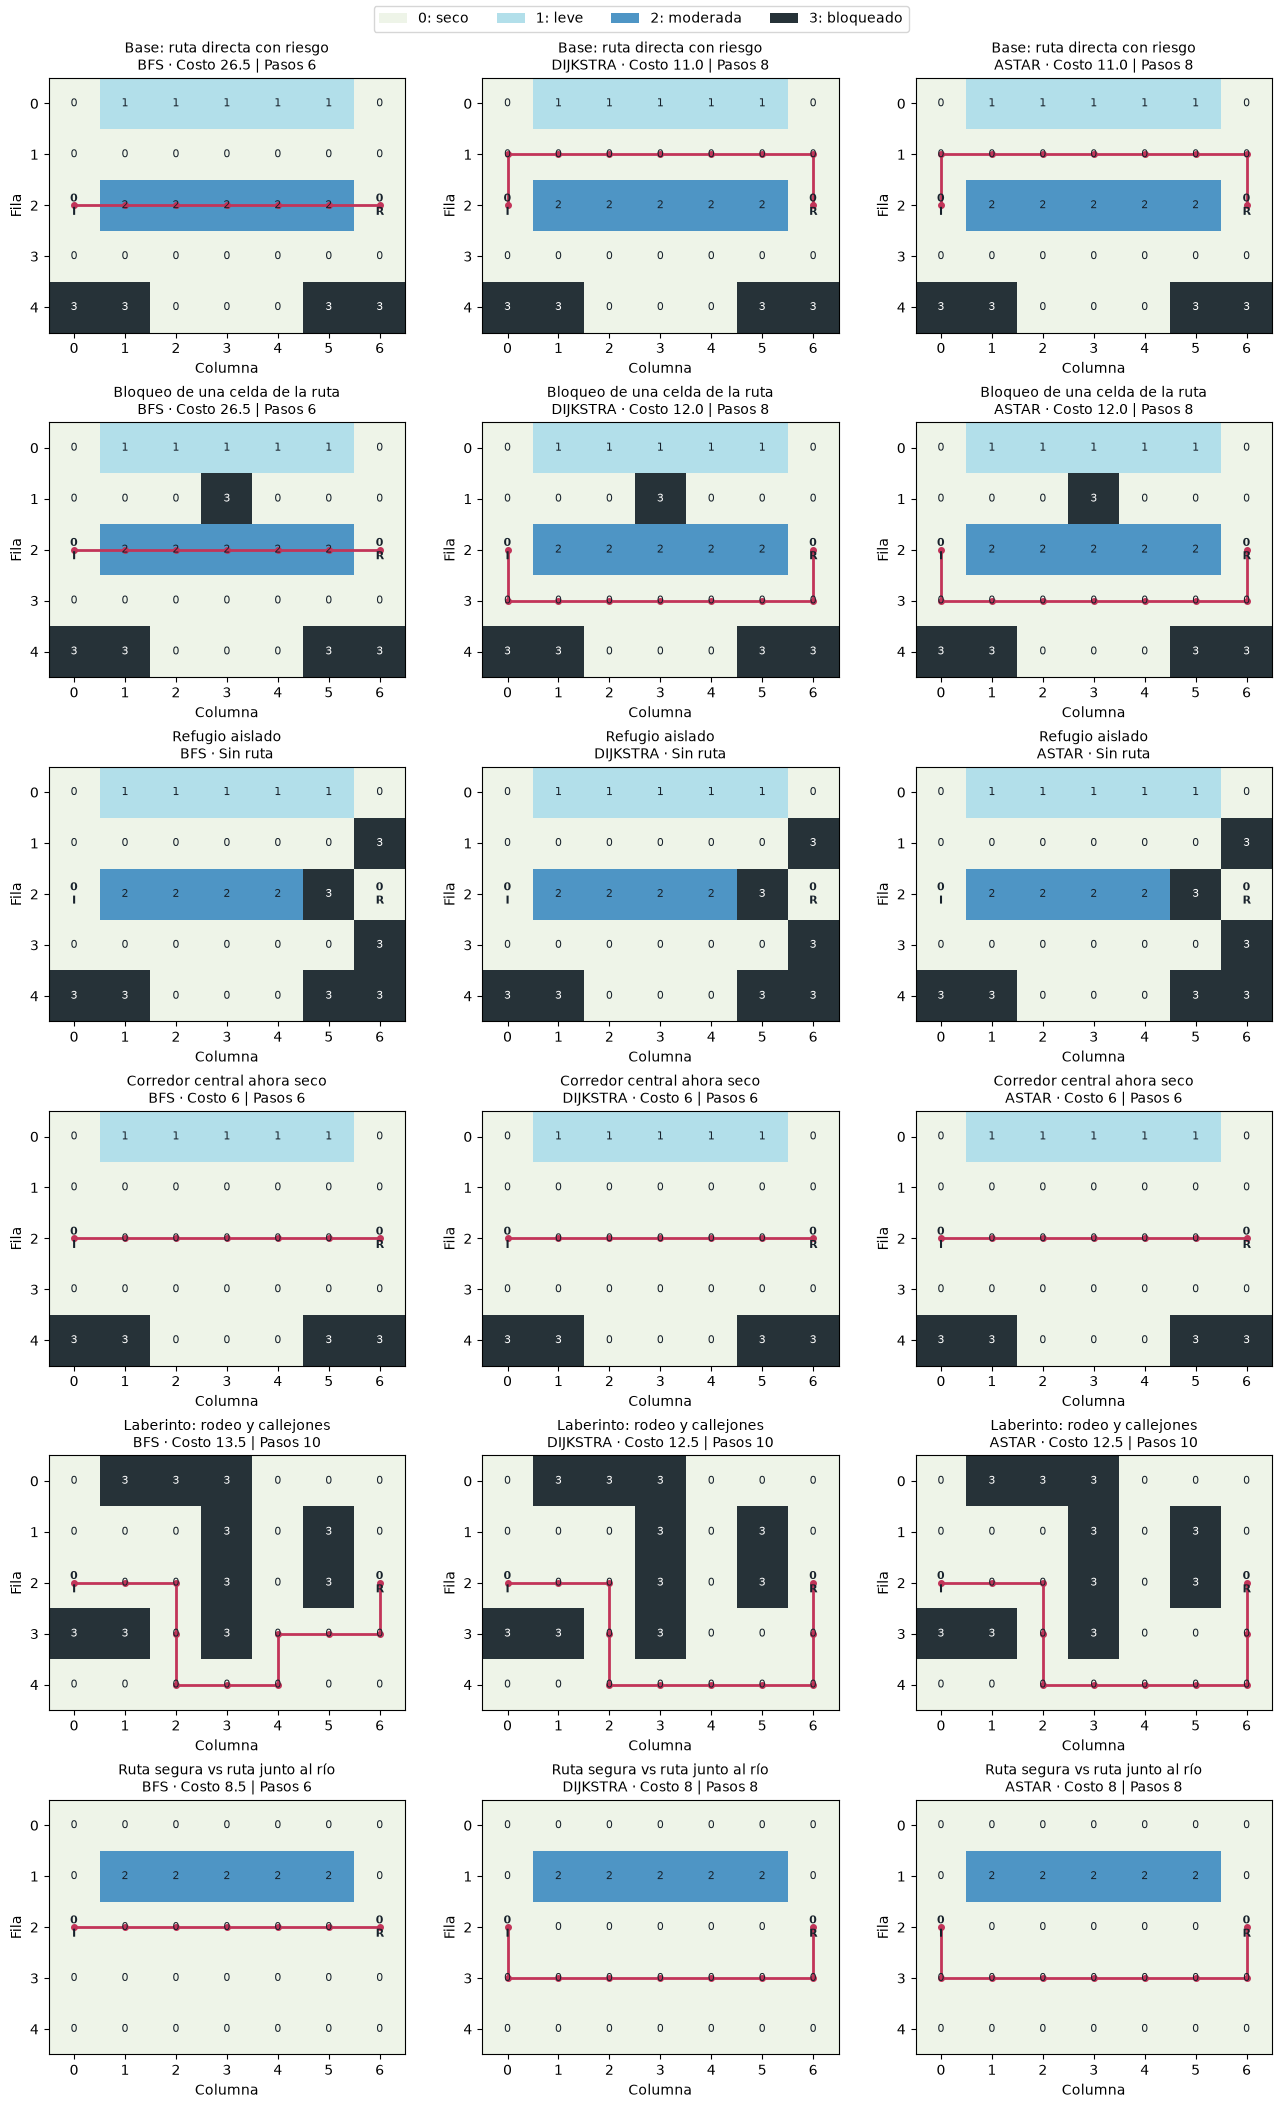

Nodos expandidos (escenario base):
BFS: 25
DIJKSTRA: 28
ASTAR: 17


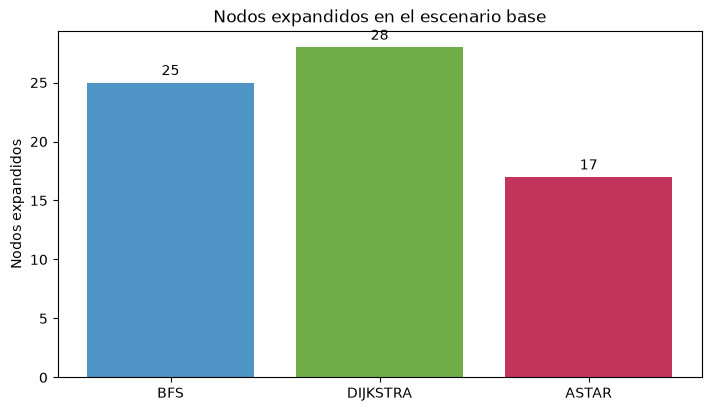

In [3]:
from pathlib import Path
import csv
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

SALIDA = Path('resultados')
SALIDA.mkdir(exist_ok=True)
COLORES = ['#eef4e8', '#b2dfea', '#4e95c5', '#263238']
fig, ejes = plt.subplots(len(ESCENARIOS), 3, figsize=(13, 21), layout='constrained')
for fila, (nombre, terreno) in enumerate(ESCENARIOS.items()):
    for columna, estrategia in enumerate(ESTRATEGIAS):
        ax = ejes[fila, columna]
        ax.imshow(terreno, cmap=ListedColormap(COLORES),
                  norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], 4))
        for f, niveles in enumerate(terreno):
            for c, nivel in enumerate(niveles):
                etiqueta = f'{nivel}\nI' if (f, c) == INICIO else (
                    f'{nivel}\nR' if (f, c) == REFUGIO else str(nivel))
                ax.text(c, f, etiqueta, ha='center', va='center', fontsize=8,
                        color='white' if nivel == 3 else '#17212b',
                        fontweight='bold' if (f, c) in (INICIO, REFUGIO) else 'normal')
        resultado = resultados[nombre][estrategia]
        m = metricas(terreno, resultado, ALFA)
        if resultado.ruta is not None:
            ax.plot([p[1] for p in resultado.ruta], [p[0] for p in resultado.ruta],
                    '-o', color='#c23459', markersize=4, linewidth=2)
        estado = 'Sin ruta' if resultado.ruta is None else f"Costo {m['costo']} | Pasos {m['pasos']}"
        ax.set_title(f"{nombre}\n{estrategia.upper()} · {estado}", fontsize=10)
        ax.set_xticks(range(len(terreno[0])))
        ax.set_yticks(range(len(terreno)))
        ax.set_xlabel('Columna')
        ax.set_ylabel('Fila')
fig.legend(handles=[Patch(facecolor=c, label=t) for c, t in zip(
    COLORES, ['0: seco', '1: leve', '2: moderada', '3: bloqueado'])],
    loc='outside upper center', ncol=4)
fig.savefig(SALIDA / 'rutas.png', dpi=140)
plt.show()

expansiones_base = [resultados['Base: ruta directa con riesgo'][e].expandidos for e in ESTRATEGIAS]
fig_exp, ax_exp = plt.subplots(figsize=(7, 4), layout='constrained')
ax_exp.bar([e.upper() for e in ESTRATEGIAS], expansiones_base, color=['#4e95c5', '#70ad47', '#c23459'])
ax_exp.set_title('Nodos expandidos en el escenario base')
ax_exp.set_ylabel('Nodos expandidos')
ax_exp.bar_label(ax_exp.containers[0], padding=3)
print('Nodos expandidos (escenario base):')
for estrategia, cantidad in zip(ESTRATEGIAS, expansiones_base):
    print(f'{estrategia.upper()}: {cantidad}')
plt.show()
with (SALIDA / 'comparacion.csv').open('w', newline='', encoding='utf-8') as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=list(filas[0]))
    escritor.writeheader()
    escritor.writerows(filas)

## Pruebas de los requisitos y regresión
Se verifican todas las rutas encontradas. Para la inaccesibilidad se comprueba
que los tres algoritmos agotan su frontera sin devolver una ruta.
La prueba adicional de **relajación** compara contra un oráculo independiente
(Bellman-Ford sobre una lista explícita de aristas) para detectar errores como
marcar un nodo definitivo al descubrirlo o usar mal la prioridad de A*.
También se introducen rutas inválidas deliberadamente para comprobar el validador,
y se prueban entradas degeneradas y el caso inicio = refugio.
Tambi?n se comprueba que A* evita el corredor seco pegado al r?o con la penalizaci?n contextual.


In [4]:
pruebas = []
def comprobar(nombre, condicion):
    assert condicion, nombre
    pruebas.append(nombre)

for nombre, terreno in ESCENARIOS.items():
    for estrategia, resultado in resultados[nombre].items():
        if nombre == 'Refugio aislado':
            comprobar(f'{nombre}/{estrategia}', resultado.ruta is None and resultado.expandidos > 0)
        else:
            comprobar(f'Ruta válida: {nombre}/{estrategia}',
                      validar_ruta(terreno, INICIO, REFUGIO, resultado.ruta))

nombre_base = next(iter(ESCENARIOS))
base_bfs = metricas(BASE, resultados[nombre_base]['bfs'], ALFA)
base_opt = metricas(BASE, resultados[nombre_base]['astar'], ALFA)
comprobar('El camino corto no minimiza el costo',
          base_bfs['pasos'] < base_opt['pasos'] and base_bfs['costo'] > base_opt['costo'])
bloqueado = ESCENARIOS['Bloqueo de una celda de la ruta']
comprobar('El bloqueo invalida la ruta anterior',
          not validar_ruta(bloqueado, INICIO, REFUGIO, ruta_previa))
for estrategia in ESTRATEGIAS:
    comprobar(f'Evita nueva celda bloqueada: {estrategia}',
              CELDA_BLOQUEADA not in resultados['Bloqueo de una celda de la ruta'][estrategia].ruta)
seco = ESCENARIOS['Corredor central ahora seco']
seco_opt = resultados['Corredor central ahora seco']['astar']
comprobar('El riesgo cambia la decisión', seco_opt.ruta != ruta_previa)
comprobar('Corredor seco tiene costo mínimo Manhattan', metricas(seco, seco_opt, ALFA)['costo'] == 6)
nombre_segura = next(n for n in ESCENARIOS if n.startswith('Ruta segura vs ruta junto al'))
segura = ESCENARIOS[nombre_segura]
ruta_rio = [(2, c) for c in range(7)]
seguro_opt = resultados[nombre_segura]['astar']
metricas_seguro = metricas(segura, seguro_opt, ALFA)
costo_rio = sum(costo_entrada(segura, punto, ALFA) for punto in ruta_rio[1:])
comprobar('A* elige el rodeo seguro frente al pasillo junto al r?o',
          seguro_opt.ruta != ruta_rio and metricas_seguro['costo'] < costo_rio)
comprobar('La ruta elegida no paga penalizaci?n contextual',
          metricas_seguro['penalizacion_contextual'] == 0)
for estrategia in ESTRATEGIAS:
    igual = buscar([[2]], (0, 0), (0, 0), estrategia)
    comprobar(f'Inicio igual a refugio: {estrategia}',
              igual.ruta == [(0, 0)] and metricas([[2]], igual, ALFA)['costo'] == 0)
    comprobar(f'Extremo bloqueado: {estrategia}',
              buscar([[3]], (0, 0), (0, 0), estrategia).ruta is None)
comprobar('Validador rechaza salto', not validar_ruta([[0, 0, 0]], (0, 0), (0, 2), [(0, 0), (0, 2)]))
comprobar('Validador rechaza inundación severa',
          not validar_ruta([[0, 3, 0]], (0, 0), (0, 2), [(0, 0), (0, 1), (0, 2)]))
comprobar('Validador rechaza ruta truncada',
          not validar_ruta(BASE, INICIO, REFUGIO, [INICIO]))

for terreno, inicio, meta, alfa in [([], (0, 0), (0, 0), 2),
        ([[0], [0, 1]], (0, 0), (0, 0), 2), ([[4]], (0, 0), (0, 0), 2),
        ([[0]], (-1, 0), (0, 0), 2), ([[0]], (0, 0), (0, 0), -1),
        ([[0]], (0, 0), (0, 0), float('nan'))]:
    try:
        buscar(terreno, inicio, meta, alfa=alfa)
    except ValueError:
        pruebas.append('Entrada inválida rechazada')
    else:
        raise AssertionError('Se aceptó una entrada inválida')

def oraculo(terreno, inicio, meta, alfa):
    # No reutiliza vecinos(), reconstruir() ni la lógica de prioridad.
    nodos = [(f, c) for f in range(len(terreno)) for c in range(len(terreno[0]))
             if terreno[f][c] != 3]
    if inicio not in nodos or meta not in nodos:
        return inf
    aristas = []
    for u in nodos:
        for v in nodos:
            if abs(u[0]-v[0]) + abs(u[1]-v[1]) != 1:
                continue
            nivel = terreno[v[0]][v[1]]
            adyacente_riesgoso = (nivel == 0 and any(
                0 <= v[0]+df < len(terreno)
                and 0 <= v[1]+dc < len(terreno[0])
                and terreno[v[0]+df][v[1]+dc] >= 2
                for df, dc in ((-1, 0), (0, 1), (1, 0), (0, -1))))
            peso = 1 + alfa * nivel + BETA * adyacente_riesgoso
            aristas.append((u, v, peso))
    dist = {p: inf for p in nodos}
    dist[inicio] = 0
    for _ in range(len(nodos)-1):
        cambio = False
        for u, v, peso in aristas:
            if dist[u] + peso < dist[v]:
                dist[v] = dist[u] + peso
                cambio = True
        if not cambio:
            break
    return dist[meta]

def oraculo_pasos(terreno, inicio, meta):
    nodos = [(f, c) for f in range(len(terreno)) for c in range(len(terreno[0]))
             if terreno[f][c] != 3]
    if inicio not in nodos or meta not in nodos:
        return inf
    dist = {p: inf for p in nodos}
    dist[inicio] = 0
    for _ in range(len(nodos)-1):
        cambio = False
        for u in nodos:
            for v in nodos:
                if (abs(u[0]-v[0]) + abs(u[1]-v[1]) == 1
                        and dist[u] + 1 < dist[v]):
                    dist[v] = dist[u] + 1
                    cambio = True
        if not cambio:
            break
    return dist[meta]

rng = random.Random(2026)
for caso in range(60):
    mapa = [[rng.choice([0, 0, 1, 2, 3]) for _ in range(5)] for _ in range(5)]
    mapa[0][0] = mapa[4][4] = 0
    for alfa in (0, 0.5, 2, 5):
        esperado = oraculo(mapa, (0, 0), (4, 4), alfa)
        esperado_pasos = oraculo_pasos(mapa, (0, 0), (4, 4))
        for estrategia in ('dijkstra', 'astar'):
            r = buscar(mapa, (0, 0), (4, 4), estrategia, alfa)
            obtenido = metricas(mapa, r, alfa)['costo']
            comprobar(f'Oráculo caso {caso}, alfa {alfa}, {estrategia}',
                      (obtenido is None and esperado == inf) or obtenido == esperado)
            if r.ruta is not None:
                comprobar(f'Validez aleatoria {caso}/{alfa}/{estrategia}',
                          validar_ruta(mapa, (0, 0), (4, 4), r.ruta))
        bfs = buscar(mapa, (0, 0), (4, 4), 'bfs', alfa)
        if alfa == 0:
            pasos_bfs = metricas(mapa, bfs, alfa)['pasos']
            comprobar(f'BFS minimiza pasos: {caso}',
                      (pasos_bfs is None and esperado_pasos == inf) or pasos_bfs == esperado_pasos)
(SALIDA / 'pruebas.txt').write_text(
    f'{len(pruebas)} comprobaciones superadas.\n' + '\n'.join(pruebas), encoding='utf-8')


30344

In [5]:
buscar_original = buscar
nombre_prueba = 'El validador detecta la ruta inv\u00e1lida inyectada'
try:
    def buscar_con_ruta_invalida(*args, **kwargs):
        return Resultado([(0, 0), (0, 2)], 1)

    buscar = buscar_con_ruta_invalida
    terreno_prueba = [[0, 0, 0]]
    ruta_inyectada = buscar(terreno_prueba, (0, 0), (0, 2), 'bfs').ruta
    try:
        comprobar(nombre_prueba,
                  validar_ruta(terreno_prueba, (0, 0), (0, 2), ruta_inyectada))
    except AssertionError as error:
        assert str(error) == nombre_prueba
    else:
        raise AssertionError('La prueba no detect\u00f3 la ruta inv\u00e1lida inyectada.')
finally:
    buscar = buscar_original

pruebas.append(nombre_prueba)
(SALIDA / 'pruebas.txt').write_text(
    f'{len(pruebas)} comprobaciones superadas.\n' + '\n'.join(pruebas) + '\n', encoding='utf-8')
print(f'{len(pruebas)} comprobaciones superadas; 60 mapas aleatorios con semilla 2026.')
print('La prueba del sistema atrap\u00f3 la ruta inv\u00e1lida inyectada y restaur\u00f3 buscar().')


959 comprobaciones superadas; 60 mapas aleatorios con semilla 2026.
La prueba del sistema atrapó la ruta inválida inyectada y restauró buscar().


## Sensibilidad al riesgo y conclusiones a partir de la ejecución
En el escenario base, la ruta directa cuesta `6 + 10*alfa`. El desvio seco
cuesta `8 + 6*BETA` porque seis celdas secas colindan con el rio. Con
`BETA=0.5`, ambas opciones empatan en `alfa=0.5`; el barrido siguiente
muestra la decision de A* y su penalizacion contextual.


In [6]:
print('alfa | pasos | exposicion | contexto | costo | expandidos')
for alfa in (0, 0.1, 0.2, 0.5, 2, 5):
    r = buscar(BASE, INICIO, REFUGIO, 'astar', alfa)
    m = metricas(BASE, r, alfa)
    print(alfa, m['pasos'], m['exposicion'], m['penalizacion_contextual'],
          m['costo'], m['expandidos'], sep=' | ')
print(f"\nCon alfa={ALFA}, BFS: {base_bfs['pasos']} pasos, costo {base_bfs['costo']}; "
      f"A*: {base_opt['pasos']} pasos, costo {base_opt['costo']}.")
for nombre, terreno in ESCENARIOS.items():
    d = metricas(terreno, resultados[nombre]['dijkstra'], ALFA)
    a = metricas(terreno, resultados[nombre]['astar'], ALFA)
    assert d['costo'] == a['costo']
    print(f"{nombre}: Dijkstra expande {d['expandidos']}; A* expande {a['expandidos']}.")


alfa | pasos | exposicion | contexto | costo | expandidos
0 | 6 | 10 | 0.5 | 6.5 | 7
0.1 | 6 | 10 | 0.5 | 7.5 | 7
0.2 | 6 | 10 | 0.5 | 8.5 | 10
0.5 | 8 | 0 | 3.0 | 11.0 | 23
2 | 8 | 0 | 3.0 | 11.0 | 17
5 | 8 | 0 | 3.0 | 11.0 | 16

Con alfa=2, BFS: 6 pasos, costo 26.5; A*: 8 pasos, costo 11.0.
Base: ruta directa con riesgo: Dijkstra expande 28; A* expande 17.
Bloqueo de una celda de la ruta: Dijkstra expande 22; A* expande 17.
Refugio aislado: Dijkstra expande 27; A* expande 27.
Corredor central ahora seco: Dijkstra expande 23; A* expande 7.
Laberinto: rodeo y callejones: Dijkstra expande 21; A* expande 17.
Ruta segura vs ruta junto al río: Dijkstra expande 27; A* expande 13.


## Análisis empírico de nodos expandidos
Se compara el trabajo observado de Dijkstra y A* en mapas con 20% de bloqueos,
semilla fija y extremos conectados. La gráfica mide expansiones, no tiempo de
ejecución ni complejidad asintótica.


Tamaño | Expandidos Dijkstra | Expandidos A*
     5 |                  14 |             10
    10 |                  75 |             57
    15 |                 177 |            176
    20 |                 318 |            314
    25 |                 496 |            492
    30 |                 710 |            701


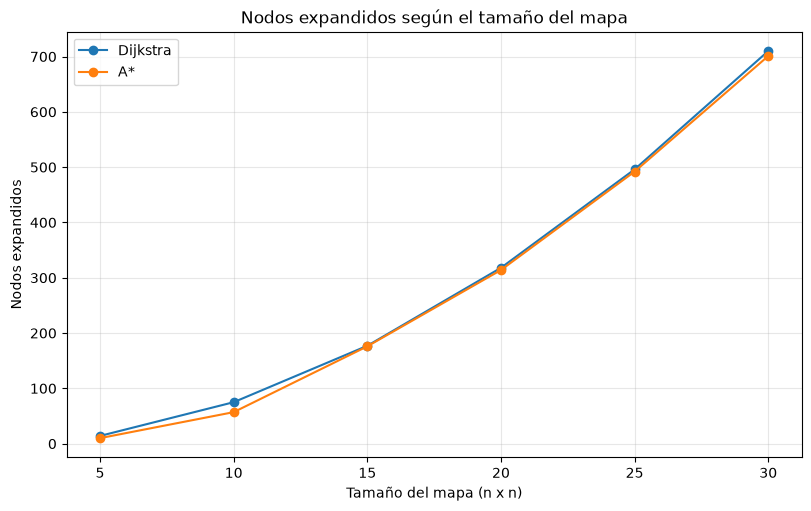

In [7]:
import random
import matplotlib.pyplot as plt

rng_rendimiento = random.Random(42)
tamanos = (5, 10, 15, 20, 25, 30)
expandidos_dijkstra = []
expandidos_astar = []

for tamano in tamanos:
    posiciones_bloqueables = [(f, c) for f in range(tamano) for c in range(tamano)
                              if (f, c) not in ((0, 0), (tamano - 1, tamano - 1))]
    cantidad_bloqueadas = tamano * tamano // 5
    while True:
        bloqueadas = set(rng_rendimiento.sample(posiciones_bloqueables,
                                                cantidad_bloqueadas))
        terreno = [[rng_rendimiento.choice((0, 1, 2)) for _ in range(tamano)]
                   for _ in range(tamano)]
        for f, c in bloqueadas:
            terreno[f][c] = 3
        terreno[0][0] = terreno[-1][-1] = 0
        inicio_rendimiento, refugio_rendimiento = (0, 0), (tamano - 1, tamano - 1)
        resultado_dijkstra = buscar(terreno, inicio_rendimiento,
                                    refugio_rendimiento, 'dijkstra', alfa=2)
        resultado_astar = buscar(terreno, inicio_rendimiento,
                                 refugio_rendimiento, 'astar', alfa=2)
        if resultado_dijkstra.ruta is not None and resultado_astar.ruta is not None:
            break
    expandidos_dijkstra.append(resultado_dijkstra.expandidos)
    expandidos_astar.append(resultado_astar.expandidos)

print('Tamaño | Expandidos Dijkstra | Expandidos A*')
for tamano, dijkstra, astar in zip(tamanos, expandidos_dijkstra, expandidos_astar):
    print(f'{tamano:6} | {dijkstra:19} | {astar:14}')

fig_rendimiento, ax_rendimiento = plt.subplots(figsize=(8, 5), layout='constrained')
ax_rendimiento.plot(tamanos, expandidos_dijkstra, marker='o', label='Dijkstra')
ax_rendimiento.plot(tamanos, expandidos_astar, marker='o', label='A*')
ax_rendimiento.set_title('Nodos expandidos según el tamaño del mapa')
ax_rendimiento.set_xlabel('Tamaño del mapa (n x n)')
ax_rendimiento.set_ylabel('Nodos expandidos')
ax_rendimiento.set_xticks(tamanos)
ax_rendimiento.grid(True, alpha=0.3)
ax_rendimiento.legend()
fig_rendimiento.savefig(SALIDA / 'rendimiento.png', dpi=140)
plt.show()


## Interpretación, límites y reproducibilidad
La salida anterior permite distinguir **encontrar una ruta** de **encontrar una
ruta conveniente bajo el criterio elegido**. BFS atraviesa el corredor de riesgo
por ser corto; Dijkstra y A* aceptan un desvío cuando reduce el costo. Al secarse
el corredor cambia la ruta óptima, y al aislar el refugio se devuelve `None`,
sin ruta ni costo ficticio. La cantidad de nodos expandidos permite comparar
el esfuerzo; el mapa pequeño no permite generalizar un rendimiento superior.

La inundación es estática durante cada búsqueda. No se modelan velocidad del agua,
capacidad del refugio, tiempo, accesibilidad personal ni incertidumbre. Si las
condiciones cambian se ejecuta de nuevo. Alfa es una preferencia de simulación;
no es un coeficiente calibrado con datos reales. Los 60 mapas sintéticos amplían
la verificación, pero no prueban corrección para todos los mapas posibles.

La grafica de rendimiento registra expansiones en seis tamanos de mapa; los
resultados son evidencia empirica para esas instancias y no una prueba de
complejidad asintotica.

### Herramientas de IA y verificación
Se utilizó **Codex de OpenAI** y Orus,  para redactar código, documentación, escenarios y
pruebas. La entrega se verificó ejecutando todas las celdas, validando restricciones
de las rutas y comparando costos con un oráculo Bellman-Ford independiente.
Las tablas y figuras provienen de esas ejecuciones; no son mediciones estimadas.
El equipo debe revisar, entender y poder explicar el material antes de entregarlo.
Consultar README.md para reproducir la ejecución e historial Git para los cambios.
